# Tutorial 02 — GPU batching

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/uw-ipd/tmol/blob/master/docs/tutorial/02_gpu_batching.ipynb)

We want to score several structures together and know that batching preserves their results. By the end, we will have a mixed-size batch whose scores agree with separate calls, plus a way to measure which layout suits our machine.

**We will:**

1. Batch four copies of a small ubiquitin fragment and check their scores.
2. Combine three different proteins and compare batched with individual scores.
3. Optionally measure padding, runtime, and memory for different layouts and sizes.

Start with [loading structures](01_working_with_tmol.ipynb). The examples run on CPU; GPU performance measurements require CUDA.


## Setup

In Colab, choose a **GPU runtime** and **Run all**. For local execution, follow the [installation guide](../installation.md) with the documentation extras. Run cells in order; setup selects CUDA when available, otherwise CPU.

Timings use a 20-residue ubiquitin fragment with `no_optH=True`; the mixed-size example uses complete structures with optimized hydrogens.


In [1]:
try:
    import google.colab  # noqa: F401
except ImportError:
    IN_COLAB = False
else:
    IN_COLAB = True

if IN_COLAB:
    from urllib.request import urlopen

    exec(
        urlopen(
            "https://raw.githubusercontent.com/uw-ipd/tmol/"
            "master/docs/tutorial/colab_setup.py"
        ).read(),
        globals(),
    )
    setup_colab(
        [
            "tmol/tests/data/cif/1UBQ.cif",
            "tmol/tests/data/cif/1R21.cif",
            "tmol/tests/data/cif/1BL8.cif",
        ]
    )


In [2]:
import logging

# The example files do not need local PDB or CCD mirrors.
logging.getLogger("atomworks.constants").addFilter(
    lambda record: not record.getMessage().startswith(
        (
            "Environment variable CCD_MIRROR_PATH not set.",
            "Environment variable PDB_MIRROR_PATH not set.",
        )
    )
)

from contextlib import redirect_stderr, redirect_stdout
from io import StringIO
from pathlib import Path
import platform
from time import perf_counter
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from IPython.display import display
from biotite.structure import AtomArrayStack
from biotite.structure.io import load_structure

import tmol
from tmol.io import biotite_from_pose_stack, pose_stack_from_biotite
from tmol.pose import PoseStackBuilder
from tmol.score import beta2016_score_function

SEED = 20260807
np.random.seed(SEED)
torch.manual_seed(SEED)

device = (
    torch.device("cuda", torch.cuda.current_device())
    if tmol.has_cuda() and torch.cuda.is_available()
    else torch.device("cpu")
)
repo_root = next(
    (
        path
        for path in (Path.cwd(), *Path.cwd().parents)
        if (path / "tmol/tests/data").is_dir()
    ),
    Path(tmol.__file__).resolve().parents[1],
)
if not (repo_root / "tmol/tests/data/cif/1UBQ.cif").exists():
    repo_root = Path(tmol.__file__).resolve().parents[1]
cif_path = repo_root / "tmol/tests/data/cif/1UBQ.cif"

from itables import show as show_table

# Format displayed numbers without changing the values used in calculations.
pd.options.display.float_format = "{:.4g}".format


## Load a small structure for batching

Use the first 20 residues of ubiquitin. This creates a new terminal fragment and keeps the timing experiment small. Missing hydrogens are built, but `no_optH=True` skips their optimization.


In [3]:
atom_array = load_structure(str(cif_path), model=1, include_bonds=True)
protein_slice = atom_array[
    (atom_array.chain_id == "A") & (atom_array.res_id <= 20)
]
with redirect_stdout(StringIO()), redirect_stderr(StringIO()):
    single_pose = pose_stack_from_biotite(protein_slice, device, no_optH=True)
score_function = beta2016_score_function(device)


print(f"benchmark device: {device}; input: {cif_path.name}")


benchmark device: cpu; input: 1UBQ.cif


## Score four structures at once

`PoseStackBuilder.from_poses()` combines poses into a batch. Four copies make it easy to check the result: the batch should return four equal scores. The first coordinate axis grows from one pose to four. Rendering a scorer prepares it for that batch’s atom layout; calling it on the coordinates returns the scores.


In [4]:
preview_batch = PoseStackBuilder.from_poses([single_pose] * 4, device)
print("single coords:", tuple(single_pose.coords.shape))
print("batch coords: ", tuple(preview_batch.coords.shape))
print("batch poses:  ", preview_batch.n_poses)
preview_scorer = score_function.render_whole_pose_scoring_module(preview_batch)
preview_scores = preview_scorer(preview_batch.coords)
show_table(
    pd.DataFrame(
        {"pose": range(4), "score": preview_scores.detach().cpu().numpy()}
    )
)
torch.testing.assert_close(
    preview_scores, preview_scores[0].expand_as(preview_scores)
)


single coords: (1, 327, 3)
batch coords:  (4, 327, 3)
batch poses:   4


## Mix structures of different sizes

Now load three complete structures: 1UBQ, 1R21, and 1BL8. Use model 1 of each and optimize hydrogens with `no_optH=False` before scoring. The three scores should match scores computed separately.

TMol may add missing atoms or omit unsupported material; this input's potassium ion in 1BL8 is omitted. The preparation table records net atom-count changes. Absolute totals across these different proteins are not a useful ranking.


In [5]:
structure_specs = [
    ("1UBQ — ubiquitin", "1UBQ.cif"),
    ("1R21 — model 1", "1R21.cif"),
    ("1BL8", "1BL8.cif"),
]
individual_poses = {}
preparation_records = {}
for label, filename in structure_specs:
    structure_file = load_structure(
        str(repo_root / "tmol" / "tests" / "data" / "cif" / filename),
        include_bonds=True,
    )
    if isinstance(structure_file, AtomArrayStack):
        deposited_model_count = structure_file.stack_depth()
        structure = structure_file[0]
    else:
        deposited_model_count = 1
        structure = structure_file

    with redirect_stdout(StringIO()), redirect_stderr(StringIO()):
        pose = pose_stack_from_biotite(structure, device, no_optH=False)
    individual_poses[label] = pose
    tmol_built_structure = biotite_from_pose_stack(pose)
    preparation_records[label] = {
        "deposited_models": deposited_model_count,
        "selected_model": 1,
        "deposited_atoms": structure.array_length(),
        "TMol_built_atoms": tmol_built_structure.array_length(),
        "net_atom_count_change": (
            tmol_built_structure.array_length() - structure.array_length()
        ),
        "count_interpretation": (
            "net filtering plus selected/built chemistry; no per-atom provenance"
        ),
        "preparation": "no_optH=False (OptH optimized)",
        "known_excluded_material": "K ion" if filename == "1BL8.cif" else "",
    }


### Score the mixed batch

Build one scorer for this batch layout. The output order follows the input order.


In [6]:
heterogeneous_batch = PoseStackBuilder.from_poses(
    list(individual_poses.values()), device
)
heterogeneous_scorer = score_function.render_whole_pose_scoring_module(
    heterogeneous_batch
)
with warnings.catch_warnings(), torch.no_grad():
    warnings.filterwarnings("ignore", message=r"Sparse index lookup.*")
    heterogeneous_scores = (
        heterogeneous_scorer(heterogeneous_batch.coords).detach().cpu().numpy()
    )


### Check against separate calls

Score each pose on its own and assert that batching preserves its total.


In [7]:
independent_scores = []
with warnings.catch_warnings(), torch.no_grad():
    warnings.filterwarnings("ignore", message=r"Sparse index lookup.*")
    for pose in individual_poses.values():
        independent_scorer = score_function.render_whole_pose_scoring_module(
            pose
        )
        independent_score = (
            independent_scorer(pose.coords).detach().cpu().numpy()
        )
        independent_scores.append(float(independent_score.reshape(-1)[0]))
independent_scores = np.asarray(independent_scores)
np.testing.assert_allclose(
    heterogeneous_scores,
    independent_scores,
    rtol=1e-5,
    atol=1e-3,
)


The table records preparation and score agreement. Switch structures in the viewer to connect each batch index with its input.


In [8]:
batch_rows = []
for pose_index, (label, pose) in enumerate(individual_poses.items()):
    preparation = preparation_records[label]
    batch_rows.append(
        {
            "pose_index": pose_index,
            "structure": label,
            **preparation,
            "blocks": pose.max_n_blocks,
            "pose_atoms": pose.max_n_pose_atoms,
            "batched_weighted_score": float(heterogeneous_scores[pose_index]),
            "independent_weighted_score": float(
                independent_scores[pose_index]
            ),
            "absolute_score_difference": float(
                abs(
                    heterogeneous_scores[pose_index]
                    - independent_scores[pose_index]
                )
            ),
        }
    )
batch_frame = pd.DataFrame(batch_rows)
show_table(
    batch_frame[
        [
            "pose_index",
            "structure",
            "blocks",
            "batched_weighted_score",
            "absolute_score_difference",
        ]
    ]
)
show_table(pd.DataFrame(preparation_records).T)
print(
    "maximum batched-vs-independent absolute difference:",
    f"{batch_frame['absolute_score_difference'].max():.6g}",
)
display(
    tmol.switchable_view(
        individual_poses,
        notes={
            row["structure"]: (
                f"batch index {row['pose_index']}; model {row['selected_model']} of "
                f"{row['deposited_models']}; {row['blocks']} blocks; "
                f"score {row['batched_weighted_score']:.3f}; optimized H"
            )
            for row in batch_rows
        },
    )
)


maximum batched-vs-independent absolute difference: 0


## What the batch check establishes

The four-copy batch returns equal scores, and the mixed batch agrees with individual calls. We can now choose a batch layout for speed and memory without changing what is scored. The timing experiments below help make that choice on this machine.


## Optional: measure batching performance

The examples above establish that batching preserves scores. The remaining sections compare layouts and batch sizes; keep this machine information with any timing results. Batch timings depend on the hardware, software versions, and competing work on the device.


In [9]:
metadata = {
    "platform": platform.platform(),
    "python": platform.python_version(),
    "tmol": tmol.__version__,
    "torch": torch.__version__,
    "device": str(device),
    "cuda_runtime": torch.version.cuda,
    "torch_threads": torch.get_num_threads(),
    "seed": SEED,
}
if device.type == "cuda":
    props = torch.cuda.get_device_properties(device)
    metadata.update(
        {
            "gpu_name": props.name,
            "compute_capability": f"{props.major}.{props.minor}",
            "gpu_memory_GiB": props.total_memory / 2**30,
        }
    )
metadata_frame = pd.DataFrame.from_dict(
    metadata, orient="index", columns=["value"]
)
show_table(metadata_frame.reset_index(names="property"))


## Compare one mixed batch with three size groups

A batch pads every member to the largest structure. Grouping similar sizes can save memory, but it also requires more scoring calls.

Score the same six poses in two layouts: one mixed batch, or three pairs of equally sized structures. Check that the scores agree before comparing timings.


In [10]:
workload_labels = [label for label in individual_poses for _ in range(2)]
workload_poses = [individual_poses[label] for label in workload_labels]
layout_groups = {
    "one heterogeneous batch": [workload_poses],
    "three size buckets": [
        [individual_poses[label], individual_poses[label]]
        for label in individual_poses
    ],
}


### Build and time each layout

These helpers build one scorer per group, concatenate scores in input order, warm up, and synchronize CUDA around each timed workload.


In [11]:
def build_layout(groups):
    """Build all batches and rendered scorers for one workload layout."""
    batches = [PoseStackBuilder.from_poses(group, device) for group in groups]
    scorers = [
        score_function.render_whole_pose_scoring_module(batch)
        for batch in batches
    ]
    return batches, scorers


def run_layout(batches, scorers):
    """Score each pre-rendered group and concatenate in workload order."""
    return torch.cat(
        [
            scorer(batch.coords)
            for batch, scorer in zip(batches, scorers, strict=True)
        ]
    )


def time_layout(batches, scorers, repeats, warmup):
    """Measure aggregate latency for all calls in one workload layout."""
    with torch.no_grad():
        for _ in range(warmup):
            run_layout(batches, scorers)
        if device.type == "cuda":
            torch.cuda.synchronize(device)
            baseline_bytes = torch.cuda.memory_allocated(device)
            torch.cuda.reset_peak_memory_stats(device)
        else:
            baseline_bytes = np.nan
        elapsed = []
        for _ in range(repeats):
            if device.type == "cuda":
                torch.cuda.synchronize(device)
            start_time = perf_counter()
            run_layout(batches, scorers)
            if device.type == "cuda":
                torch.cuda.synchronize(device)
            elapsed.append(perf_counter() - start_time)
    if device.type == "cuda":
        incremental_peak_bytes = max(
            0, torch.cuda.max_memory_allocated(device) - baseline_bytes
        )
    else:
        incremental_peak_bytes = np.nan
    return 1e3 * np.asarray(elapsed), incremental_peak_bytes


### Verify identical work

Both layouts must return the same six scores in the same order.


In [12]:
built_layouts = {
    label: build_layout(groups) for label, groups in layout_groups.items()
}
with torch.no_grad():
    layout_scores = {
        label: run_layout(*layout).detach().cpu()
        for label, layout in built_layouts.items()
    }
torch.testing.assert_close(
    layout_scores["one heterogeneous batch"],
    layout_scores["three size buckets"],
    rtol=1e-5,
    atol=1e-3,
)


### Measure padding, latency, and memory

Count useful atoms versus allocated slots, then time repeated scoring of each complete layout. CUDA peak allocation here is measured above the post-warmup baseline.


In [13]:
useful_atoms = sum(
    int(pose.real_atoms.sum().item()) for pose in workload_poses
)
useful_blocks = sum(
    int((pose.block_type_ind64 >= 0).sum().item()) for pose in workload_poses
)
layout_rows = []
layout_repeats = 7 if device.type == "cuda" else 2
layout_warmup = 3 if device.type == "cuda" else 1
for label, (batches, scorers) in built_layouts.items():
    elapsed_ms, incremental_peak_bytes = time_layout(
        batches,
        scorers,
        repeats=layout_repeats,
        warmup=layout_warmup,
    )
    atom_slots = sum(
        batch.n_poses * batch.max_n_pose_atoms for batch in batches
    )
    block_slots = sum(batch.n_poses * batch.max_n_blocks for batch in batches)
    layout_rows.append(
        {
            "layout": label,
            "score_calls_per_workload": len(batches),
            "poses": len(workload_poses),
            "useful_atom_slots": useful_atoms,
            "rectangular_atom_slots": atom_slots,
            "atom_padding_fraction": 1.0 - useful_atoms / atom_slots,
            "useful_block_slots": useful_blocks,
            "rectangular_block_slots": block_slots,
            "block_padding_fraction": 1.0 - useful_blocks / block_slots,
            "median_total_latency_ms": float(np.median(elapsed_ms)),
            "throughput_poses_s": float(
                1e3 * len(workload_poses) / np.median(elapsed_ms)
            ),
            "latency_IQR_ms": float(
                np.percentile(elapsed_ms, 75) - np.percentile(elapsed_ms, 25)
            ),
            "incremental_peak_cuda_MiB": incremental_peak_bytes / 2**20,
            "measurement": (
                "CUDA workload timing"
                if device.type == "cuda"
                else "CPU timing; not GPU guidance"
            ),
        }
    )
layout_frame = pd.DataFrame(layout_rows)
show_table(
    layout_frame[
        [
            "layout",
            "atom_padding_fraction",
            "block_padding_fraction",
            "median_total_latency_ms",
            "incremental_peak_cuda_MiB",
        ]
    ].rename(
        columns={
            "layout": "Layout",
            "atom_padding_fraction": "Atom padding",
            "block_padding_fraction": "Block padding",
            "median_total_latency_ms": "Latency (ms)",
            "incremental_peak_cuda_MiB": "Extra CUDA memory (MiB)",
        }
    )
)


Compare wasted space and total runtime for the same six structures.


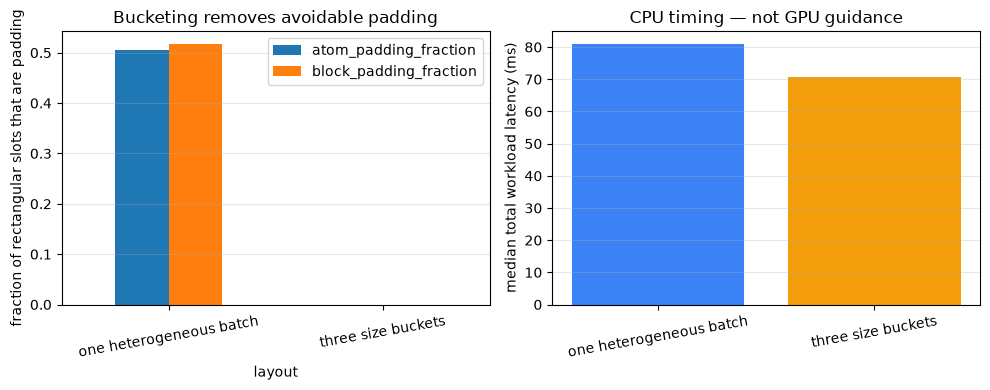

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
padding_plot = layout_frame.set_index("layout")[
    ["atom_padding_fraction", "block_padding_fraction"]
]
padding_plot.plot.bar(ax=axes[0], rot=10)
axes[0].set(
    ylabel="fraction of rectangular slots that are padding",
    title="Bucketing removes avoidable padding",
)
axes[1].bar(
    layout_frame["layout"],
    layout_frame["median_total_latency_ms"],
    color=["#3b82f6", "#f59e0b"],
)
axes[1].set(
    ylabel="median total workload latency (ms)",
    title=(
        "Measured CUDA workload"
        if device.type == "cuda"
        else "CPU timing — not GPU guidance"
    ),
)
axes[1].tick_params(axis="x", rotation=10)
for axis in axes:
    axis.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()


The left plot shows unused tensor space; the right shows measured runtime. Less padding does not guarantee a faster run. Choose the layout from both measurements. CPU results describe this CPU only.


## Measure the effect of batch size

Return to the 20-residue ubiquitin fragment so only batch size changes. Build a scorer for each batch size, warm it up, then time repeated calls. CUDA synchronization ensures the timer includes completed GPU work.

The helper records median latency, the middle 50% of timings (Q1–Q3), and peak PyTorch allocation. Scorer construction is excluded from timings; memory is measured above the post-construction baseline and includes warmup.


In [15]:
def benchmark_scoring(batch_size, repeats=5, warmup=2):
    batch = PoseStackBuilder.from_poses([single_pose] * batch_size, device)
    scorer = score_function.render_whole_pose_scoring_module(batch)

    if device.type == "cuda":
        torch.cuda.synchronize(device)
        post_construction_bytes = torch.cuda.memory_allocated(device)
        torch.cuda.reset_peak_memory_stats(device)
    else:
        post_construction_bytes = np.nan

    with torch.no_grad():
        for _ in range(warmup):
            scorer(batch.coords)
        if device.type == "cuda":
            torch.cuda.synchronize(device)

        elapsed = []
        for _ in range(repeats):
            if device.type == "cuda":
                torch.cuda.synchronize(device)
            start = perf_counter()
            scorer(batch.coords)
            if device.type == "cuda":
                torch.cuda.synchronize(device)
            elapsed.append(perf_counter() - start)

    elapsed_ms = 1e3 * np.asarray(elapsed)
    latency_q1_ms, latency_q3_ms = np.percentile(elapsed_ms, [25, 75])
    latency_ms = float(np.median(elapsed_ms))
    if device.type == "cuda":
        peak_bytes = torch.cuda.max_memory_allocated(device)
        incremental_peak_bytes = max(0, peak_bytes - post_construction_bytes)
    else:
        peak_bytes = np.nan
        incremental_peak_bytes = np.nan
    return {
        "batch_size": batch_size,
        "latency_min_ms": float(elapsed_ms.min()),
        "latency_q1_ms": float(latency_q1_ms),
        "latency_ms": latency_ms,
        "latency_q3_ms": float(latency_q3_ms),
        "latency_max_ms": float(elapsed_ms.max()),
        "latency_iqr_ms": float(latency_q3_ms - latency_q1_ms),
        "throughput_poses_s": 1e3 * batch_size / latency_ms,
        "post_construction_cuda_MiB": post_construction_bytes / 2**20,
        "peak_cuda_MiB": peak_bytes / 2**20,
        "incremental_peak_cuda_MiB": incremental_peak_bytes / 2**20,
        "repeats": repeats,
    }


### Run the batch-size sweep

Use small batches on CPU and larger batches on CUDA. Record throughput as well as latency.


In [16]:
batch_sizes = [1, 4, 16, 64] if device.type == "cuda" else [1, 2, 4]
repeats = 5 if device.type == "cuda" else 2
benchmark_frame = pd.DataFrame(
    [benchmark_scoring(size, repeats=repeats) for size in batch_sizes]
)


The table reports median batch latency and throughput. Error bars in the plots below show the middle half of the timing measurements.


In [17]:
benchmark_frame["latency_per_pose_ms"] = (
    benchmark_frame["latency_ms"] / benchmark_frame["batch_size"]
)
benchmark_frame["latency_per_pose_q1_ms"] = (
    benchmark_frame["latency_q1_ms"] / benchmark_frame["batch_size"]
)
benchmark_frame["latency_per_pose_q3_ms"] = (
    benchmark_frame["latency_q3_ms"] / benchmark_frame["batch_size"]
)
benchmark_frame["throughput_q1_poses_s"] = (
    1e3 * benchmark_frame["batch_size"] / benchmark_frame["latency_q3_ms"]
)
benchmark_frame["throughput_q3_poses_s"] = (
    1e3 * benchmark_frame["batch_size"] / benchmark_frame["latency_q1_ms"]
)
benchmark_frame["throughput_vs_batch_1"] = (
    benchmark_frame["throughput_poses_s"]
    / benchmark_frame.loc[0, "throughput_poses_s"]
)
benchmark_frame.insert(
    0,
    "measurement",
    "CUDA throughput" if device.type == "cuda" else "CPU example",
)
show_table(
    benchmark_frame[
        [
            "batch_size",
            "latency_ms",
            "throughput_poses_s",
            "latency_iqr_ms",
            "incremental_peak_cuda_MiB",
        ]
    ].rename(
        columns={
            "batch_size": "Batch size",
            "latency_ms": "Latency (ms)",
            "throughput_poses_s": "Poses / s",
            "latency_iqr_ms": "Timing IQR (ms)",
            "incremental_peak_cuda_MiB": "Extra CUDA memory (MiB)",
        }
    )
)


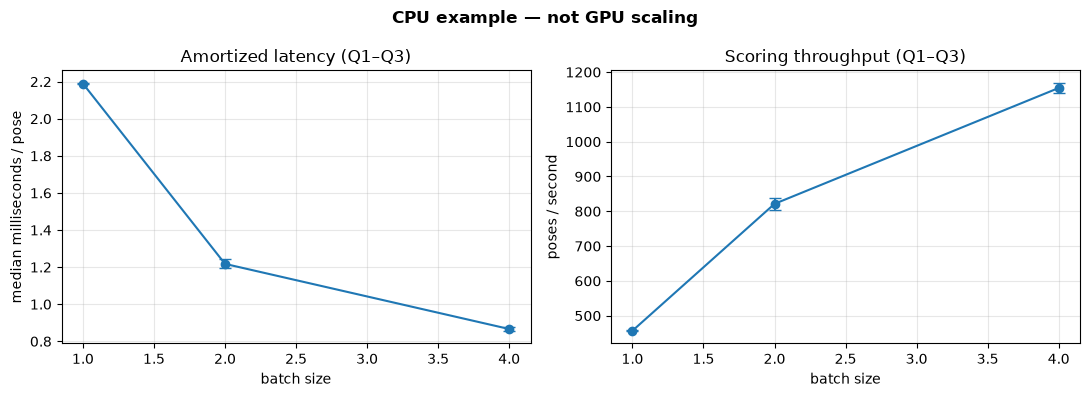

In [18]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
latency_yerr = np.vstack(
    [
        benchmark_frame["latency_per_pose_ms"]
        - benchmark_frame["latency_per_pose_q1_ms"],
        benchmark_frame["latency_per_pose_q3_ms"]
        - benchmark_frame["latency_per_pose_ms"],
    ]
)
axes[0].errorbar(
    benchmark_frame["batch_size"],
    benchmark_frame["latency_per_pose_ms"],
    yerr=latency_yerr,
    marker="o",
    capsize=4,
)
axes[0].set(
    xlabel="batch size",
    ylabel="median milliseconds / pose",
    title="Amortized latency (Q1–Q3)",
)
throughput_yerr = np.vstack(
    [
        benchmark_frame["throughput_poses_s"]
        - benchmark_frame["throughput_q1_poses_s"],
        benchmark_frame["throughput_q3_poses_s"]
        - benchmark_frame["throughput_poses_s"],
    ]
)
axes[1].errorbar(
    benchmark_frame["batch_size"],
    benchmark_frame["throughput_poses_s"],
    yerr=throughput_yerr,
    marker="o",
    capsize=4,
)
axes[1].set(
    xlabel="batch size",
    ylabel="poses / second",
    title="Scoring throughput (Q1–Q3)",
)
for axis in axes:
    axis.grid(alpha=0.3)
fig.suptitle(
    (
        "Measured CUDA batching"
        if device.type == "cuda"
        else "CPU example — not GPU scaling"
    ),
    fontweight="bold",
)
plt.tight_layout()
plt.show()


Read the plots together: milliseconds per pose is batch latency divided by batch size; poses per second is its reciprocal. Error bars show Q1–Q3. A falling per-pose cost means batching is helping on this machine.

## Try a larger CUDA batch

This cell times 128 copies. It is skipped on CPU.


In [ ]:
# | tags: [gpu-only]
# gpu-only: this capacity point is omitted on CPU.
if device.type != "cuda":
    print("Skipped: this cell requires CUDA.")
    gpu_capacity_point = None
else:
    gpu_capacity_point = benchmark_scoring(128, repeats=5, warmup=2)
    show_table(pd.DataFrame([gpu_capacity_point]))


## Use the measurements to choose a batch size

The memory columns report live allocation after construction, the peak during warmup and scoring, and their difference. They cover PyTorch allocations, not all GPU process memory.

Leave room for other work. If the input is too large, score it in chunks and retain only the results you need. For several GPUs, assign chunks to separate processes with an external scheduler; TMol does not schedule them.


## Try it

1. Increase the timing repeats and see whether the error bars stabilize.
2. Change the size groups and compare both padding and runtime.
3. Score a list in chunks, concatenate the totals, and check them against one small unchunked batch.


## Next

Use [scoring and analysis](03_scoring_and_analysis.ipynb) to inspect terms and block-pair contributions.


## References

- [TMol repository](https://github.com/uw-ipd/tmol)
- [PyTorch CUDA semantics](https://pytorch.org/docs/stable/notes/cuda.html)
- [PyTorch benchmarking recipe](https://pytorch.org/tutorials/recipes/recipes/benchmark.html)
